# Secondary Structure & Dihedrals — All Frames
## MUC2 Long PTS | Glycosylated vs Non-glycosylated

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors

base       = "/home/computer2/analysis_simulations/analysis/secondrystructure_allframes/"
output_dir = "/home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots"
os.makedirs(output_dir, exist_ok=True)

RES_OFFSET = 1377   # index 0 = residue 1377
CLR_GLY    = "#2E86AB"
CLR_NOG    = "#A23B72"

print("Ready. Output:", output_dir)

Ready. Output: /home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots


## Load Data

In [2]:
# SS fraction per residue — updated files now include I_frac (π-helix)
ss_gly  = np.genfromtxt(base + "ss_fraction_glycans.dat",   dtype=None, encoding="utf-8", names=True)
ss_nog  = np.genfromtxt(base + "ss_fraction_noglycans.dat", dtype=None, encoding="utf-8", names=True)

# Dihedrals mean/std all frames
dih   = np.genfromtxt(base + "dihedrals_mean_std_comparison.dat", comments="#")
omega = np.genfromtxt(base + "omega_comparison_allframes.dat",    comments="#")

res_idx = ss_gly['residue_index'].astype(int) + RES_OFFSET
N_FRAMES = 2381   # frames per system

# All-frame phi/psi
print("Loading phi/psi all frames...")
phi_gly_all = np.genfromtxt(base + "phi_all_glycans.dat",   skip_header=1, usecols=3)
psi_gly_all = np.genfromtxt(base + "psi_all_glycans.dat",   skip_header=1, usecols=3)
phi_nog_all = np.genfromtxt(base + "phi_all_noglycans.dat", skip_header=1, usecols=3)
psi_nog_all = np.genfromtxt(base + "psi_all_noglycans.dat", skip_header=1, usecols=3)
print(f"Loaded {len(phi_gly_all):,} glycans | {len(phi_nog_all):,} noglycans phi values")

# Report all non-zero SS types
print("\nNon-zero SS types:")
for col in ss_gly.dtype.names:
    if 'frac' not in col:
        continue
    g = ss_gly[col].astype(float)
    n = ss_nog[col].astype(float)
    if g.max() > 0 or n.max() > 0:
        print(f"  {col:10s}  glyc mean={g.mean()*100:.2f}% max={g.max()*100:.2f}%  |  "
              f"nog mean={n.mean()*100:.2f}% max={n.max()*100:.2f}%")

Loading phi/psi all frames...
Loaded 271,434 glycans | 271,434 noglycans phi values

Non-zero SS types:
  H_frac      glyc mean=0.00% max=0.00%  |  nog mean=0.10% max=1.09%
  E_frac      glyc mean=0.00% max=0.00%  |  nog mean=0.07% max=0.34%
  C_frac      glyc mean=95.00% max=100.00%  |  nog mean=74.26% max=100.00%
  G_frac      glyc mean=0.01% max=0.29%  |  nog mean=0.30% max=1.47%
  I_frac      glyc mean=0.00% max=0.00%  |  nog mean=0.00% max=0.04%
  T_frac      glyc mean=0.17% max=3.32%  |  nog mean=3.79% max=22.34%
  B_frac      glyc mean=0.00% max=0.00%  |  nog mean=0.10% max=0.92%
  S_frac      glyc mean=4.81% max=26.54%  |  nog mean=21.37% max=49.90%


## Figure 1 — Ramachandran Plot (All Frames)

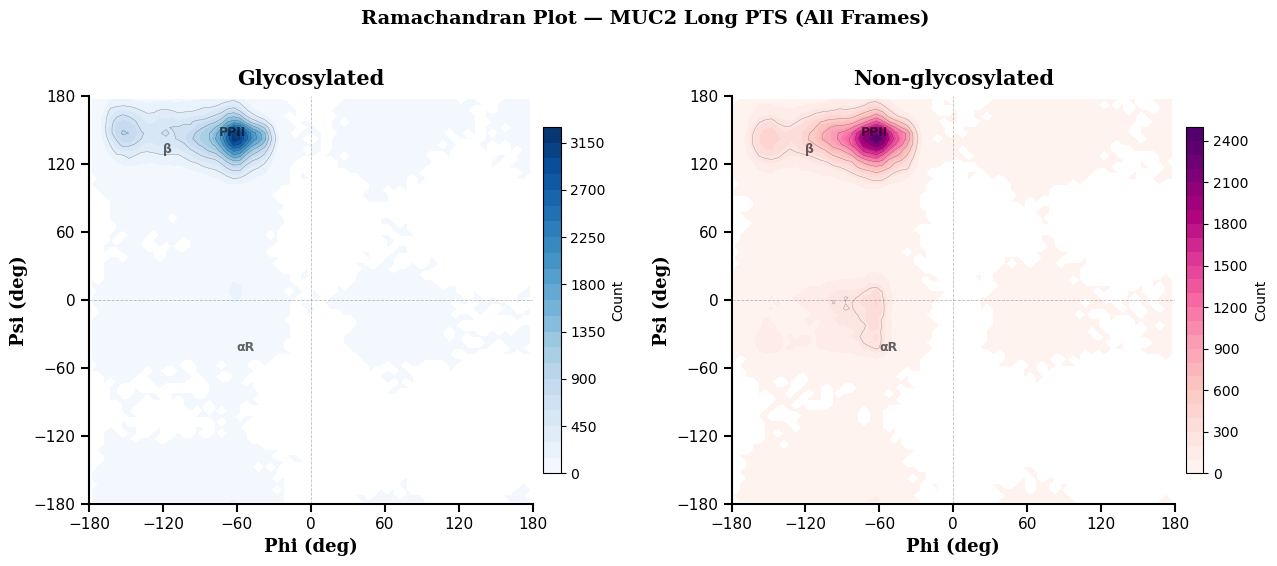

Saved: /home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots/ramachandran_allframes.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=100)
fig.set_facecolor("white")

bins = np.linspace(-180, 180, 73)

for ax, phi, psi, title, cmap in [
    (axes[0], phi_gly_all, psi_gly_all, "Glycosylated",     "Blues"),
    (axes[1], phi_nog_all, psi_nog_all, "Non-glycosylated",  "RdPu"),
]:
    h, xe, ye = np.histogram2d(phi, psi, bins=bins)
    h = np.where(h == 0, np.nan, h)
    xc = 0.5 * (xe[:-1] + xe[1:])
    yc = 0.5 * (ye[:-1] + ye[1:])

    im = ax.contourf(xc, yc, h.T, levels=25, cmap=cmap)
    ax.contour(xc, yc, h.T, levels=10, colors="black", linewidths=0.3, alpha=0.4)
    plt.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label="Count")

    # Region labels
    ax.text(-75, 145,  "PPII",   fontsize=9, color="black", fontweight="bold", alpha=0.6)
    ax.text(-120, 130, "\u03B2", fontsize=9, color="black", fontweight="bold", alpha=0.6)
    ax.text(-60, -45,  "\u03B1R",fontsize=9, color="black", fontweight="bold", alpha=0.6)

    ax.axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.25)
    ax.axvline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.25)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-180, 180)
    ax.set_xlabel("Phi (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Psi (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=15, fontname="DejaVu Serif", fontweight="bold", pad=8)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(labelsize=11, length=6, width=1.5, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(60))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(60))

fig.suptitle("Ramachandran Plot — MUC2 Long PTS (All Frames)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(output_dir, "ramachandran_allframes.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 2 — Secondary Structure Fraction per Residue

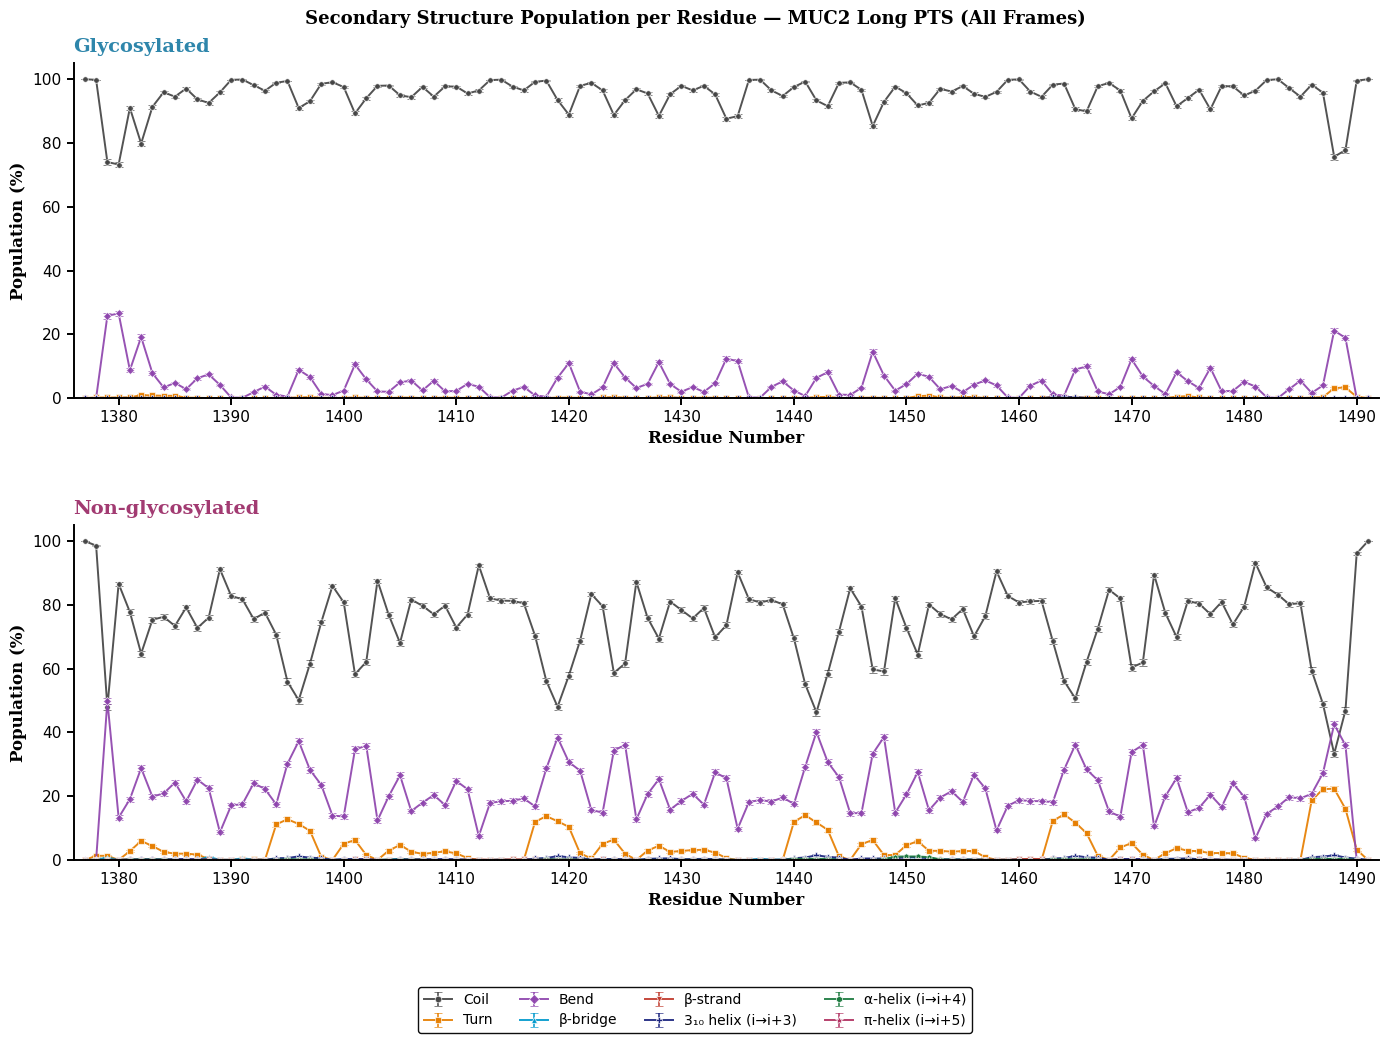

Saved: /home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots/ss_fraction_per_residue.png


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), dpi=100)
fig.set_facecolor("white")

# All DSSP/STRIDE helix & SS types — ordered by structural complexity
ss_styles = {
    "C_frac": {"label": "Coil",          "color": "#444444", "marker": "o", "ms": 4},
    "T_frac": {"label": "Turn",          "color": "#E67E00", "marker": "s", "ms": 4},
    "S_frac": {"label": "Bend",          "color": "#8E44AD", "marker": "D", "ms": 4},
    "B_frac": {"label": "\u03B2-bridge", "color": "#0099CC", "marker": "^", "ms": 4},
    "E_frac": {"label": "\u03B2-strand", "color": "#C0392B", "marker": "v", "ms": 4},
    "G_frac": {"label": "3\u2081\u2080 helix (i\u2192i+3)", "color": "#1A237E", "marker": "P", "ms": 4},
    "H_frac": {"label": "\u03B1-helix (i\u2192i+4)",       "color": "#1B7A3E", "marker": "h", "ms": 4},
    "I_frac": {"label": "\u03C0-helix (i\u2192i+5)",       "color": "#B03060", "marker": "*", "ms": 5},
}

handles_collected = []

for ax, dat, system_label, sys_color in [
    (axes[0], ss_gly, "Glycosylated",    CLR_GLY),
    (axes[1], ss_nog, "Non-glycosylated", CLR_NOG),
]:
    for col, style in ss_styles.items():
        if col not in dat.dtype.names:
            continue
        p   = dat[col].astype(float)
        pct = p * 100
        se  = np.sqrt(p * (1 - p) / N_FRAMES) * 100
        if pct.max() < 0.001:          # truly absent — skip
            continue
        h = ax.errorbar(res_idx, pct, yerr=se,
                        color=style["color"], marker=style["marker"],
                        markersize=style["ms"], linewidth=1.4,
                        markerfacecolor=style["color"],
                        markeredgewidth=0.5, markeredgecolor="white",
                        elinewidth=1.2, capsize=3, capthick=1.2,
                        ecolor=style["color"], alpha=0.92,
                        label=style["label"])
        if ax is axes[0]:
            handles_collected.append(h)

    ax.set_title(system_label, fontsize=14, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=8, loc="left")
    ax.set_ylabel("Population (%)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlabel("Residue Number", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlim(res_idx[0] - 1, res_idx[-1] + 1)
    ax.set_ylim(0, 105)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(20))
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

# Rebuild handle list from noglycans panel (has most types) for complete legend
handles_all, labels_all = axes[1].get_legend_handles_labels()
fig.legend(handles=handles_all, labels=labels_all,
           loc="lower center", bbox_to_anchor=(0.5, -0.05),
           ncol=4, fontsize=10, framealpha=0.95,
           edgecolor="black", markerscale=1.2)

fig.suptitle("Secondary Structure Population per Residue — MUC2 Long PTS (All Frames)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(hspace=0.38, bottom=0.13)
out = os.path.join(output_dir, "ss_fraction_per_residue.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 3 — Overall Secondary Structure Summary

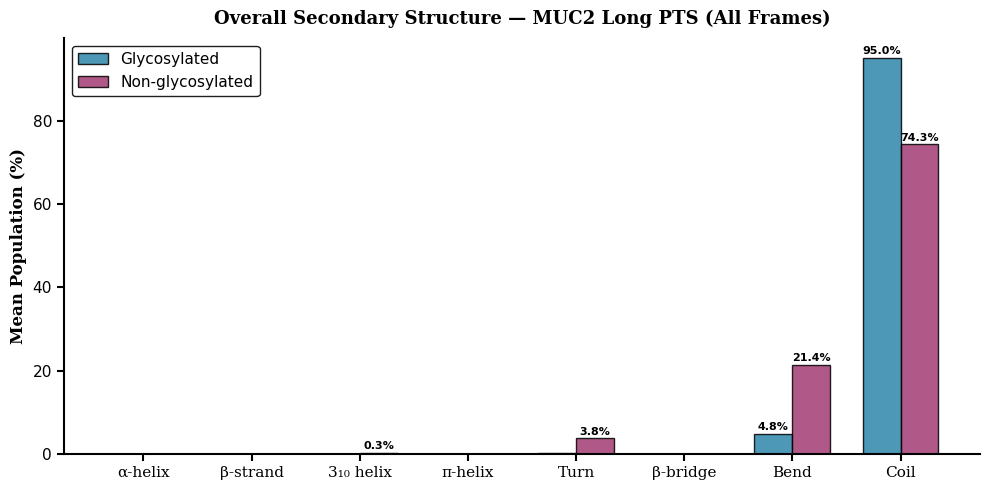

Saved: /home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots/ss_overall_summary.png


In [5]:
ss_code_labels = {
    "H_frac": "\u03B1-helix",
    "E_frac": "\u03B2-strand",
    "G_frac": "3\u2081\u2080 helix",
    "I_frac": "\u03C0-helix",
    "T_frac": "Turn",
    "B_frac": "\u03B2-bridge",
    "S_frac": "Bend",
    "C_frac": "Coil",
}
ss_colors_bar = {
    "H_frac": "#1B7A3E", "E_frac": "#C0392B", "G_frac": "#1A237E",
    "I_frac": "#B03060", "T_frac": "#E67E00", "B_frac": "#0099CC",
    "S_frac": "#8E44AD", "C_frac": "#444444",
}

names, pct_gly, pct_nog = [], [], []
for col, label in ss_code_labels.items():
    if col not in ss_gly.dtype.names:
        continue
    g = float(ss_gly[col].astype(float).mean() * 100)
    n = float(ss_nog[col].astype(float).mean() * 100)
    if g > 0 or n > 0:
        names.append(label)
        pct_gly.append(g)
        pct_nog.append(n)

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
fig.set_facecolor("white")

x = np.arange(len(names))
w = 0.35
bars1 = ax.bar(x - w/2, pct_gly, width=w, color=CLR_GLY, alpha=0.85,
               edgecolor="black", linewidth=1.0, label="Glycosylated")
bars2 = ax.bar(x + w/2, pct_nog, width=w, color=CLR_NOG, alpha=0.85,
               edgecolor="black", linewidth=1.0, label="Non-glycosylated")

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    if h > 0.3:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.4,
                f"{h:.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=11, fontname="DejaVu Serif")
ax.set_ylabel("Mean Population (%)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Overall Secondary Structure — MUC2 Long PTS (All Frames)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=11, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.tight_layout()
out = os.path.join(output_dir, "ss_overall_summary.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 4 — Per-residue Mean Phi/Psi with Std Dev (All Frames)

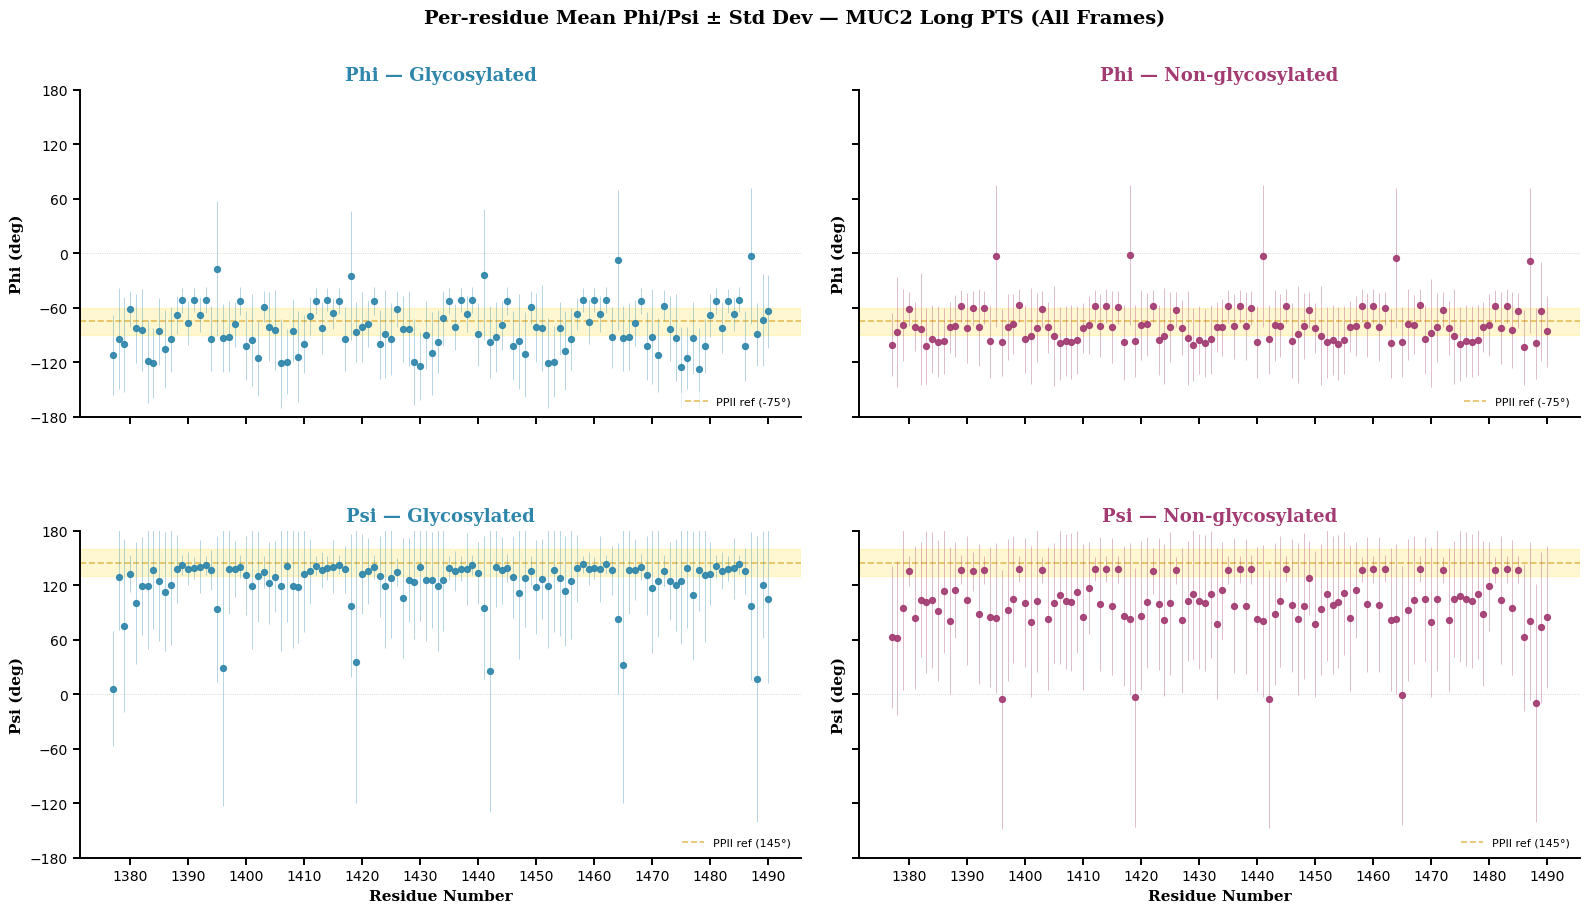

Saved: /home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots/per_residue_dihedrals_allframes.png


In [6]:
res_dih = dih[:, 0].astype(int) + RES_OFFSET
phi_gly_m = dih[:, 1];  phi_gly_s = dih[:, 2]
phi_nog_m = dih[:, 3];  phi_nog_s = dih[:, 4]
psi_gly_m = dih[:, 6];  psi_gly_s = dih[:, 7]
psi_nog_m = dih[:, 8];  psi_nog_s = dih[:, 9]

PPII_PHI = -75.0
PPII_PSI = 145.0

fig, axes = plt.subplots(2, 2, figsize=(16, 9), dpi=100, sharey="row", sharex=True)
fig.set_facecolor("white")

datasets = [
    (axes[0, 0], phi_gly_m, phi_gly_s, "Phi — Glycosylated",     CLR_GLY, PPII_PHI, "Phi (deg)"),
    (axes[0, 1], phi_nog_m, phi_nog_s, "Phi — Non-glycosylated",  CLR_NOG, PPII_PHI, "Phi (deg)"),
    (axes[1, 0], psi_gly_m, psi_gly_s, "Psi — Glycosylated",     CLR_GLY, PPII_PSI, "Psi (deg)"),
    (axes[1, 1], psi_nog_m, psi_nog_s, "Psi — Non-glycosylated",  CLR_NOG, PPII_PSI, "Psi (deg)"),
]

for ax, mean_vals, std_vals, title, color, ref_val, ylabel in datasets:
    ax.axhspan(ref_val - 15, ref_val + 15, color="gold", alpha=0.18, zorder=0)
    ax.axhline(ref_val, color="goldenrod", linewidth=1.2, linestyle="--",
               alpha=0.7, zorder=1, label=f"PPII ref ({ref_val:.0f}°)")
    ax.vlines(res_dih, mean_vals - std_vals, mean_vals + std_vals,
              color=color, linewidth=0.7, alpha=0.35, zorder=2)
    ax.scatter(res_dih, mean_vals, color=color, s=18, zorder=4, alpha=0.92)
    ax.axhline(0, color="black", linewidth=0.6, linestyle=":", alpha=0.2)
    ax.set_ylim(-180, 180)
    ax.set_title(title, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=color, pad=7)
    ax.set_ylabel(ylabel, fontsize=11, fontname="DejaVu Serif", fontweight="bold")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=10, length=5, width=1.4, direction="out")
    ax.yaxis.set_major_locator(ticker.MultipleLocator(60))
    ax.legend(fontsize=8, framealpha=0.7, edgecolor="none", loc="lower right")

for ax in axes[1]:
    ax.set_xlabel("Residue Number", fontsize=11, fontname="DejaVu Serif", fontweight="bold")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))

fig.suptitle("Per-residue Mean Phi/Psi ± Std Dev — MUC2 Long PTS (All Frames)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
plt.subplots_adjust(hspace=0.35, wspace=0.08)
out = os.path.join(output_dir, "per_residue_dihedrals_allframes.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 5 — Omega Angle per Residue (Peptide Planarity)

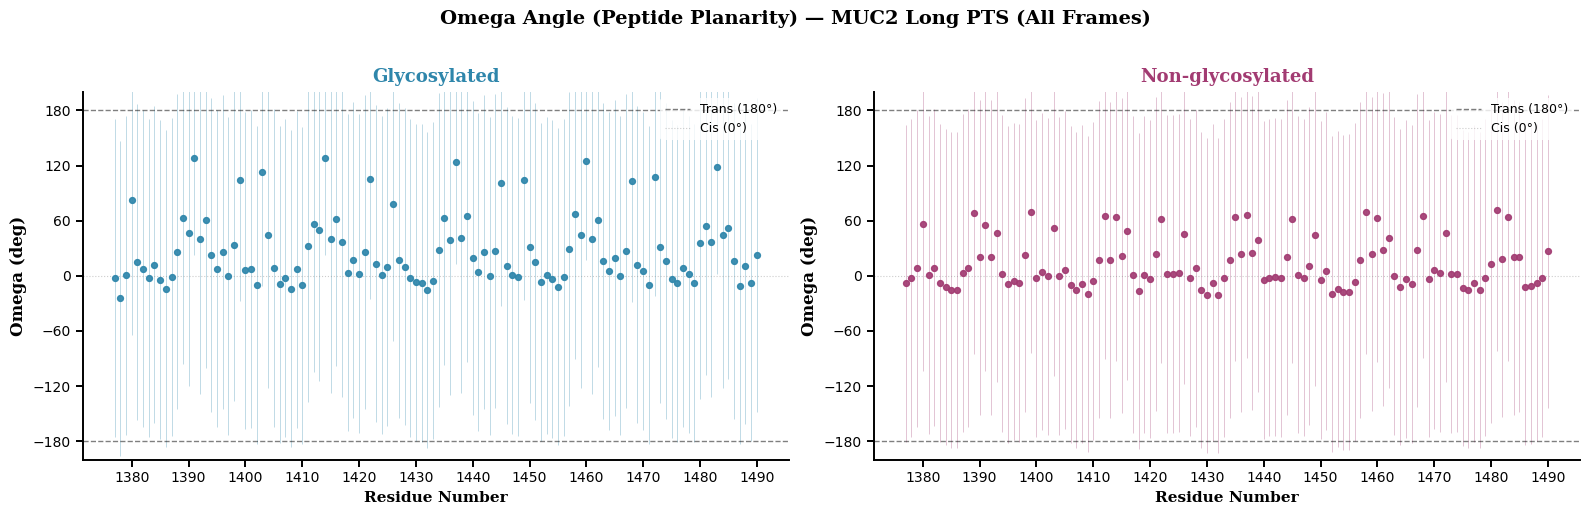

Saved: /home/computer2/analysis_simulations/analysis/secondrystructure_allframes/plots/omega_allframes.png


In [7]:
res_om    = omega[:, 0].astype(int) + RES_OFFSET
om_gly_m  = omega[:, 1];  om_gly_s = omega[:, 2]
om_nog_m  = omega[:, 3];  om_nog_s = omega[:, 4]
d_omega   = omega[:, 5]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=100, sharey=False, sharex=True)
fig.set_facecolor("white")

for ax, mean_v, std_v, title, color in [
    (axes[0], om_gly_m, om_gly_s, "Glycosylated",    CLR_GLY),
    (axes[1], om_nog_m, om_nog_s, "Non-glycosylated", CLR_NOG),
]:
    ax.vlines(res_om, mean_v - std_v, mean_v + std_v,
              color=color, linewidth=0.7, alpha=0.3, zorder=2)
    ax.scatter(res_om, mean_v, color=color, s=18, zorder=4, alpha=0.92)
    ax.axhline(180,  color="black", linewidth=1.0, linestyle="--", alpha=0.5, label="Trans (180°)")
    ax.axhline(-180, color="black", linewidth=1.0, linestyle="--", alpha=0.5)
    ax.axhline(0,    color="gray",  linewidth=0.8, linestyle=":",  alpha=0.4, label="Cis (0°)")
    ax.set_ylim(-200, 200)
    ax.set_ylabel("Omega (deg)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlabel("Residue Number", fontsize=11, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=color, pad=7)
    ax.legend(fontsize=9, framealpha=0.8, edgecolor="none")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=10, length=5, width=1.4, direction="out")
    ax.yaxis.set_major_locator(ticker.MultipleLocator(60))
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))

fig.suptitle("Omega Angle (Peptide Planarity) — MUC2 Long PTS (All Frames)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
plt.subplots_adjust(wspace=0.12)
out = os.path.join(output_dir, "omega_allframes.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")